# Spatial joins, buffers and overlays

**Series 1 · Episode 3 — Spatial Data in Python**

Four operations do most of the work in vector GIS:

| | question it answers |
|---|---|
| `sjoin` | which polygon is this point in? |
| `buffer` | what is within *N* metres of this? |
| `overlay` | what do these two layers have in common? |
| `dissolve` | merge these parts into bigger ones |


**Data:** 13,652 georeferenced road accidents in Berlin (Unfallatlas 2018),
97 neighbourhood polygons, 7,413 street segments.


In [1]:
# --- install what is missing (Colab) -----------
import importlib, subprocess, sys

for mod, pkg in [("geopandas", "geopandas"), ("mapclassify", "mapclassify"),
                 ("pyarrow", "pyarrow")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

# --- data loader ------------------
import os, urllib.request

TS = "https://raw.githubusercontent.com/tagesspiegel/Unfallatlas-Berlin-2018/master/"
URLS = {
    "accidents_berlin_2018.geojson":       TS + "unfaelle_berlin_2018.geo.json",
    "street_segments_berlin_2018.geojson": TS + "unfaelle_berlin_2018_abschnitte.geo.json",
    "berlin_ortsteile.geojson":
        "https://raw.githubusercontent.com/codeforgermany/click_that_hood/main/public/data/berlin.geojson",
    "berlin_bezirke.geojson":
        "https://raw.githubusercontent.com/m-hoerz/berlin-shapes/master/berliner-bezirke.geojson",
}

def data_path(name, folder="data"):
    """Return a local path to a course dataset, downloading it only if needed."""
    for candidate in (os.path.join(folder, name), os.path.join("..", folder, name), name):
        if os.path.exists(candidate):
            return candidate
    os.makedirs(folder, exist_ok=True)
    target = os.path.join(folder, name)
    print("downloading", name, "...")
    urllib.request.urlretrieve(URLS[name], target)
    return target


CRS_METRIC = 25833   # ETRS89 / UTM zone 33N
print("setup done")


setup done


## 1. Load, and project first

Everything below measures distance or area, so we move to metres before we
touch anything — the lesson from episode 2.


In [2]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

acc = gpd.read_file(data_path("accidents_berlin_2018.geojson")).to_crs(CRS_METRIC)
ort = gpd.read_file(data_path("berlin_ortsteile.geojson")).to_crs(CRS_METRIC)
seg = gpd.read_file(data_path("street_segments_berlin_2018.geojson")).to_crs(CRS_METRIC)

ort = ort[["name", "geometry"]]

for label, gdf in [("accidents", acc), ("neighbourhoods", ort), ("streets", seg)]:
    print(f"{label:<15} {len(gdf):>6,} rows   {gdf.geom_type.iloc[0]:<12} {gdf.crs.name}")


downloading accidents_berlin_2018.geojson ...
downloading berlin_ortsteile.geojson ...
downloading street_segments_berlin_2018.geojson ...
accidents       13,652 rows   Point        ETRS89 / UTM zone 33N
neighbourhoods      97 rows   MultiPolygon ETRS89 / UTM zone 33N
streets          7,413 rows   LineString   ETRS89 / UTM zone 33N


In [3]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(11, 10))

# draw bottom up
ort.plot(ax=ax, facecolor="#EDF3E8", edgecolor="#9DB3A1", linewidth=0.6)
seg.plot(ax=ax, color="#2C5F2D", linewidth=0.8, alpha=0.7)
acc.plot(ax=ax, color="#B85042", markersize=1.5, alpha=0.35)

# one legend entry per layer, built by hand so each shows the right symbol
handles = [
    Patch(facecolor="#EDF3E8", edgecolor="#9DB3A1",
          label=f"Neighbourhoods  (n={len(ort):,})"),
    Line2D([], [], color="#2C5F2D", linewidth=2,
           label=f"Street segments  (n={len(seg):,})"),
    Line2D([], [], color="#B85042", marker="o", linestyle="none", markersize=5,
           label=f"Accidents 2018  (n={len(acc):,})"),
]
ax.legend(handles=handles, loc="upper left", frameon=True, fontsize=10)

ax.set_axis_off()
plt.tight_layout()
plt.show()

## 2. The first join, and the rows it drops

**Which neighbourhood is each accident in?**


In [4]:
joined = gpd.sjoin(acc, ort, how="inner", predicate="within") # `how="inner"` works like a SQL inner join

print(f"accidents in   {len(acc):>7,}")
print(f"rows out       {len(joined):>7,}")
print(f"change         {len(joined) - len(acc):>+7,}")

accidents in    13,652
rows out        13,649
change              -3


In [5]:
print(acc.shape)
print(ort.shape)
print(joined.shape)

(13652, 15)
(97, 2)
(13649, 17)


In [6]:
acc.head(3)

,UMONAT,USTUNDE,UKATEGORIE,ULICHTVERH,IstRad,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstig,STRZUSTAND,bezirk,oteil,dn_id,geometry
0,01,15,3,0,0,1,1,0,0,0,1,Friedrichshain-Kreuzberg,Friedrichshain,27655,POINT (396514.638 5819257.337)
1,01,11,3,0,0,1,0,0,0,0,0,Reinickendorf,Tegel,39923,POINT (384223.623 5827729.718)
2,01,09,3,0,0,1,1,0,0,0,0,Friedrichshain-Kreuzberg,Friedrichshain,18336,POINT (392850.806 5820718.363)


In [7]:
ort.head(3)

,name,geometry
0,Rahnsdorf,"MULTIPOLYGON (((411925.088 5812415.109, 411976..."
1,Rudow,"MULTIPOLYGON (((396597.49 5811370.953, 396601...."
2,Malchow,"MULTIPOLYGON (((397521.337 5827278.299, 397563..."


In [8]:
joined.head(3)

,UMONAT,USTUNDE,UKATEGORIE,ULICHTVERH,IstRad,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstig,STRZUSTAND,bezirk,oteil,dn_id,geometry,index_right,name
0,01,15,3,0,0,1,1,0,0,0,1,Friedrichshain-Kreuzberg,Friedrichshain,27655,POINT (396514.638 5819257.337),13,Friedrichshain
1,01,11,3,0,0,1,0,0,0,0,0,Reinickendorf,Tegel,39923,POINT (384223.623 5827729.718),40,Tegel
2,01,09,3,0,0,1,1,0,0,0,0,Friedrichshain-Kreuzberg,Friedrichshain,18336,POINT (392850.806 5820718.363),13,Friedrichshain


**how="left"**

In [9]:
left = gpd.sjoin(acc, ort, how="left", predicate="within")
lost = left[left["name"].isna()]

print(f"left join rows {len(left):>7,}")
print(f"unmatched      {len(lost):>7,}")

lost

left join rows  13,652
unmatched            3


,UMONAT,USTUNDE,UKATEGORIE,ULICHTVERH,IstRad,IstPKW,IstFuss,IstKrad,IstGkfz,IstSonstig,STRZUSTAND,bezirk,oteil,dn_id,geometry,index_right,name
4501,04,16,3,0,0,1,0,0,0,0,0,Marzahn-Hellersdorf,Hellersdorf,37808,POINT (405320.513 5822771.26),NaN,NaN
5026,05,15,3,0,1,1,0,0,0,0,0,Steglitz-Zehlendorf,Wannsee,43631,POINT (372800.605 5806257.158),NaN,NaN
5339,05,07,2,0,0,1,0,0,0,0,0,Marzahn-Hellersdorf,Hellersdorf,37804,POINT (404226.162 5823099.21),NaN,NaN


Static Map

In [10]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig, ax = plt.subplots(figsize=(11, 10))

# draw bottom up: polygons, then lines, then points, then the lost ones on top
ort.plot(ax=ax, facecolor="#EDF3E8", edgecolor="#9DB3A1", linewidth=0.6)
seg.plot(ax=ax, color="#2C5F2D", linewidth=0.8, alpha=0.7)
acc.plot(ax=ax, color="#B85042", markersize=1.5, alpha=0.35)
lost.plot(ax=ax, color="none", edgecolor="black", markersize=260,
          linewidth=2.2, marker="o", zorder=5)

handles = [
    Patch(facecolor="#EDF3E8", edgecolor="#9DB3A1",
          label=f"Neighbourhoods  (n={len(ort):,})"),
    Line2D([], [], color="#2C5F2D", linewidth=2,
           label=f"Street segments  (n={len(seg):,})"),
    Line2D([], [], color="#B85042", marker="o", linestyle="none", markersize=5,
           label=f"Accidents 2018  (n={len(acc):,})"),
    Line2D([], [], color="black", marker="o", markerfacecolor="none",
           linestyle="none", markersize=11,
           label=f"Lost in the join  (n={len(lost)})"),
]
ax.legend(handles=handles, loc="upper left", frameon=True, fontsize=10)

ax.set_title("Berlin 2018 — the three accidents the join dropped", fontsize=13)
ax.set_axis_off()
plt.tight_layout()
plt.show()

**How far outside?**

In [11]:
gap = lost.geometry.apply(lambda p: ort.distance(p).min())

for idx, d in gap.items():
    print(f"accident {idx:>6}   {d:>6.1f} m outside the nearest neighbourhood")


accident   4501      7.1 m outside the nearest neighbourhood
accident   5026      1.7 m outside the nearest neighbourhood
accident   5339     10.6 m outside the nearest neighbourhood


**Plot Interactive Map**

https://geopandas.org/en/stable/docs/user_guide/interactive_mapping.html

In [12]:
import folium

map = ort.explore(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin",
    name="Neighbourhoods",
    style_kwds={"fillColor": "#EDF3E8", "color": "#9DB3A1", "weight": 1, "fillOpacity": 0.3},
    tooltip="name", highlight=False)


In [13]:

seg[["str_name", "n_total", "geometry"]].explore(
    m=map, name="Street segments", color="#2C5F2D",
    style_kwds={"weight": 2, "opacity": 0.7}, tooltip=["str_name", "n_total"])

acc[["UKATEGORIE", "USTUNDE", "oteil", "geometry"]].explore(
    m=map, name="Accidents 2018", color="#B85042",
    marker_kwds={"radius": 2}, style_kwds={"fillOpacity": 0.5, "weight": 0},
    tooltip=["UKATEGORIE", "USTUNDE", "oteil"])

lost[["oteil", "geometry"]].explore(
    m=map, name="Lost in the join", color="black",
    marker_kwds={"radius": 12}, style_kwds={"fill": False, "weight": 3},
    tooltip=["oteil"])

folium.LayerControl(collapsed=False).add_to(map)

map

## 3. Predicates: the join asks a specific question

`predicate` is the spatial test. The default is `"intersects"`, which is the
loosest one. For points inside polygons, `"within"` says what you mean.


In [14]:
for predicate in ["intersects", "within", "contains"]:
    n = len(gpd.sjoin(acc, ort, how="inner", predicate=predicate))
    print(f"{predicate:<12} {n:>7,} rows")

intersects    13,649 rows
within        13,649 rows
contains           0 rows


Predicates are relationships between a **left** and a **right** layer, so the
order of the arguments is part of the question.


In [15]:
flipped = gpd.sjoin(ort, acc, how="inner", predicate="contains")
print(f"sjoin(ort, acc, 'contains')   {len(flipped):>7,} rows")
print(f"sjoin(acc, ort, 'within')     {len(joined):>7,} rows")
print()
print("same pairs, different row orientation:",
      len(flipped) == len(joined))


sjoin(ort, acc, 'contains')    13,649 rows
sjoin(acc, ort, 'within')      13,649 rows

same pairs, different row orientation: True


## 4. Buffer

**How many accidents happened within 150 m of Frankfurter Allee?**

In [16]:
def report_join(before, after, label=""):
    delta = len(after) - len(before)
    kept = after.index.nunique()
    print(f"{label}")
    print(f"  in            {len(before):>7,}")
    print(f"  out           {len(after):>7,}   ({delta:+,})")
    print(f"  unique inputs {kept:>7,}   ({kept - len(before):+,} vs input)")
    if len(after) > kept:
        print(f" ---> {len(after) - kept:,} rows are duplicates of the same input feature")
    return after

In [17]:
street = seg[seg["str_name"] == "Frankfurter Allee"].copy()
street["geometry"] = street.geometry.buffer(150)


near = gpd.sjoin(acc, street[["str_name", "geometry"]],
                 how="inner", predicate="within")

_ = report_join(acc[acc.index.isin(near.index)], near,
                "accidents near Frankfurter Allee")


accidents near Frankfurter Allee
  in                159
  out               381   (+222)
  unique inputs     159   (+0 vs input)
 ---> 222 rows are duplicates of the same input feature


**381 rows, but only 159 accidents**

**dissolve**

The fix is to decide what one row should mean. If the answer is "one accident",
merge the buffers into a single shape **before** joining.


In [18]:
merged = street.dissolve(by="str_name")[["geometry"]].reset_index()

print(f"{len(street)} segment buffers -> {len(merged)} merged shape")

near_ok = gpd.sjoin(acc, merged, how="inner", predicate="within")

_ = report_join(acc[acc.index.isin(near_ok.index)], near_ok,
                "accidents near Frankfurter Allee (merged buffer)")


19 segment buffers -> 1 merged shape
accidents near Frankfurter Allee (merged buffer)
  in                159
  out               159   (+0)
  unique inputs     159   (+0 vs input)


Same question, same data, one row per accident.

If you need to keep the per-segment rows for another reason, count unique inputs
instead of rows — `near.index.nunique()` — but never report `len(near)` as a
number of accidents.


In [19]:
import folium

m = ort.explore(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin",
    name="Neighbourhoods",
    style_kwds={"fillColor": "#EDF3E8", "color": "#9DB3A1", "weight": 1, "fillOpacity": 0.3},
    tooltip="name", highlight=False)

merged.boundary.explore(
    m=m, name="merged buffer", color="#7C5F5D", linewidth=1.8, linestyle="--")

seg[["str_name", "n_total", "geometry"]].explore(
    m=m, name="Street segments", color="#2C5F2D",
    style_kwds={"weight": 2, "opacity": 0.7}, tooltip=["str_name", "n_total"])

street[["str_name", "n_total", "geometry"]].explore(
    m=m, name="Frankfurt Alley", color="#2C5F2D",
    style_kwds={"weight": 2, "opacity": 0.7}, tooltip=["str_name", "n_total"])

acc[["UKATEGORIE", "USTUNDE", "oteil", "geometry"]].explore(
    m=m, name="Accidents 2018", color="#B85042",
    marker_kwds={"radius": 2}, style_kwds={"fillOpacity": 0.5, "weight": 0},
    tooltip=["UKATEGORIE", "USTUNDE", "oteil"])


folium.LayerControl(collapsed=False).add_to(m)
m

## 5. Overlay: cutting one layer by another


**How much of each neighbourhood lies within 5 km of Alexanderplatz?**


In [20]:
from shapely.geometry import Point

alex = gpd.GeoSeries([Point(13.4132, 52.5219)], crs=4326).to_crs(CRS_METRIC).iloc[0]
ring = gpd.GeoDataFrame({"zone": ["inner city"]},
                        geometry=[alex.buffer(5000)], crs=CRS_METRIC)

inner = gpd.overlay(ort, ring, how="intersection")

print(f"neighbourhoods touched   {len(inner):>6}")
print(f"area inside the ring     {inner.area.sum()/1e6:>6.1f} km²")
print(f"area of the whole city   {ort.area.sum()/1e6:>6.1f} km²")


neighbourhoods touched       22
area inside the ring       78.4 km²
area of the whole city    890.7 km²


In [21]:
m = ort.explore(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, HERE, Garmin",
    name="Neighbourhoods",
    style_kwds={"fillColor": "#EDF3E8", "color": "#9DB3A1", "weight": 1, "fillOpacity": 0.3},
    tooltip="name", highlight=False)

inner.explore(
    m=m, name="inner", color="black",
    marker_kwds={"radius": 12}, style_kwds={"fill": False, "weight": 3})

folium.Marker(
    location=[52.5219, 13.4132],
    tooltip=folium.Tooltip("Alexanderplatz", permanent=True),
).add_to(m)


folium.LayerControl(collapsed=False).add_to(m)
m

❔ The ring is 8.8% of Berlin's area — what
share of its accidents does it hold?


In [22]:
in_ring = gpd.sjoin(acc, ring, how="inner", predicate="within")

area_share = inner.area.sum() / ort.area.sum()
acc_share = len(in_ring) / len(acc)

print(f"area      {area_share*100:>5.1f}% of the city")
print(f"accidents {acc_share*100:>5.1f}% of the total  ({len(in_ring):,} of {len(acc):,})")
print(f"density   {acc_share/area_share:>5.1f}× the city average")


area        8.8% of the city
accidents  34.2% of the total  (4,669 of 13,652)
density     3.9× the city average


## 6. Dissolve: Aggregation with dissolve

`dissolve` is `groupby` with geometry: it merges every polygon that shares a key
and aggregates the attributes.

Let us roll the 97 neighbourhoods up into the 12 districts. The boundary layer
has no district column, so we build the lookup from the accident table, which
carries both names.


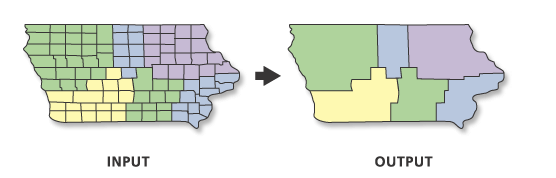

**how many accidents are in each neighbourhood?**

In [23]:
counts = joined.groupby("name").size().rename("accidents")
lookup = acc.groupby("oteil")["bezirk"].first().rename("bezirk")

ort_rich = (ort
            .merge(counts, left_on="name", right_index=True, how="left")
            .merge(lookup, left_on="name", right_index=True, how="left"))
ort_rich["accidents"] = ort_rich["accidents"].fillna(0).astype(int)

print(f"neighbourhoods         {len(ort_rich):>6}")
print(f"accidents accounted    {ort_rich['accidents'].sum():>6,}")


neighbourhoods             97
accidents accounted    13,649


In [24]:
# "bezirk" means "district"
districts = ort_rich.dissolve(by="bezirk", aggfunc={"accidents": "sum"}).reset_index()

print(f"{len(ort_rich)} neighbourhoods -> {len(districts)} districts")
print(f"accidents before dissolve  {ort_rich['accidents'].sum():>7,}")
print(f"accidents after dissolve   {districts['accidents'].sum():>7,}")
print(f"difference                 {districts['accidents'].sum() - ort_rich['accidents'].sum():>+7,}")


97 neighbourhoods -> 12 districts
accidents before dissolve   13,649
accidents after dissolve    13,626
difference                     -23


Twenty-three accidents disappeared.



In [25]:
orphan = ort_rich[ort_rich["bezirk"].isna()]
print(orphan[["name", "accidents"]].to_string(index=False))
print()
print("is this name in the accident table?",
      orphan["name"].iloc[0] in set(acc["oteil"]))


         name  accidents
Schlachtensee         23

is this name in the accident table? False


Use `dropna=False` keeps the group so you see it rather than lose it:


In [26]:
districts = (ort_rich
             .dissolve(by="bezirk", aggfunc={"accidents": "sum"}, dropna=False)
             .reset_index())

print(f"groups {len(districts)}  (12 districts + 1 unassigned)")
print(f"accidents after dissolve   {districts['accidents'].sum():>7,}")
print()
print(districts[["bezirk", "accidents"]].tail(3).to_string(index=False))

groups 13  (12 districts + 1 unassigned)
accidents after dissolve    13,649

              bezirk  accidents
Tempelhof-Schöneberg       1268
    Treptow-Köpenick        899
                 NaN         23


In [27]:
districts["area_km2"] = districts.area / 1e6
districts["per_km2"] = districts["accidents"] / districts["area_km2"]

# drop nun bezirk
top = districts.dropna(subset=["bezirk"]).nlargest(12, "per_km2")
print(top[["bezirk", "accidents", "area_km2", "per_km2"]]
      .round({"area_km2": 1, "per_km2": 1})
      .to_string(index=False))


                    bezirk  accidents  area_km2  per_km2
  Friedrichshain-Kreuzberg       1378      20.4     67.6
                     Mitte       2281      39.4     57.9
Charlottenburg-Wilmersdorf       1705      64.7     26.4
      Tempelhof-Schöneberg       1268      53.0     23.9
                  Neukölln        906      44.9     20.2
               Lichtenberg        728      52.1     14.0
                    Pankow       1280     103.2     12.4
       Marzahn-Hellersdorf        616      61.8     10.0
             Reinickendorf        879      89.3      9.8
       Steglitz-Zehlendorf        893      98.5      9.1
                   Spandau        793      91.8      8.6
          Treptow-Köpenick        899     167.6      5.4


In [28]:
import folium

plot_df = districts.dropna(subset=["bezirk"]).copy()
plot_df[["area_km2", "per_km2"]] = plot_df[["area_km2", "per_km2"]].round(1)

m = plot_df.explore(
    column="per_km2", cmap="YlOrRd", tiles=None, name="Accident density",
    legend=True, legend_kwds={"caption": "accidents per km²"},
    style_kwds={"color": "white", "weight": 1, "fillOpacity": 0.9},
    tooltip=["bezirk", "accidents", "area_km2", "per_km2"])

ring.boundary.explore(
    m=m, name="5 km around Alexanderplatz", color="#2C5F2D",
    style_kwds={"weight": 3, "dashArray": "8 6"}, tooltip=False)

folium.LayerControl(collapsed=False).add_to(m)
m



**Next episode:** nearest-neighbour joins and geocoding, matching things that
do not overlap at all.
